# 1. Data Collecting

In [1]:
import pandas as pd

# Load dataset
df = pd.read_csv('Heart_Disease_Prediction_Dataset.csv')

In [2]:
# Display dataset's first five rows
df.head()

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


In [3]:
# Display dataset's information
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    str    
 2   ChestPainType   918 non-null    str    
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    str    
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    str    
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    str    
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), str(5)
memory usage: 97.6 KB


# 2. Exploratory Data Analysis

In [4]:
# Display dataset's statistics information
df.describe()

,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease
count,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000
mean,53.510893,132.396514,198.799564,0.233115,136.809368,0.887364,0.553377
std,9.432617,18.514154,109.384145,0.423046,25.460334,1.066570,0.497414
min,28.000000,0.000000,0.000000,0.000000,60.000000,-2.600000,0.000000
25%,47.000000,120.000000,173.250000,0.000000,120.000000,0.000000,0.000000
50%,54.000000,130.000000,223.000000,0.000000,138.000000,0.600000,1.000000
75%,60.000000,140.000000,267.000000,0.000000,156.000000,1.500000,1.000000
max,77.000000,200.000000,603.000000,1.000000,202.000000,6.200000,1.000000


In [5]:
# Separate the numerical features and the categorical features
num_cols = df.select_dtypes(include='number').columns
cat_cols = df.select_dtypes(include='object').columns

C:\Users\ThinkPad\AppData\Local\Temp\ipykernel_19364\631922960.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df.select_dtypes(include='object').columns


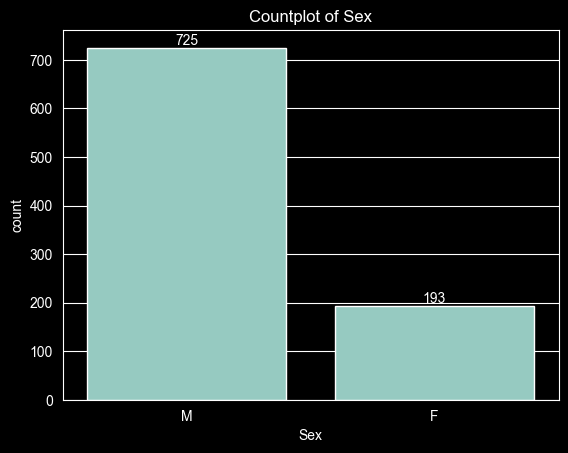

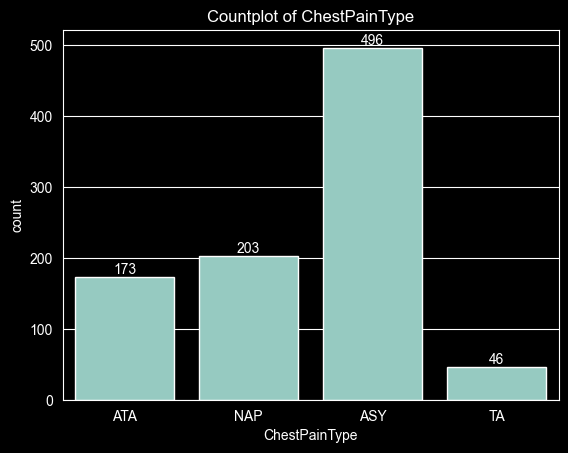

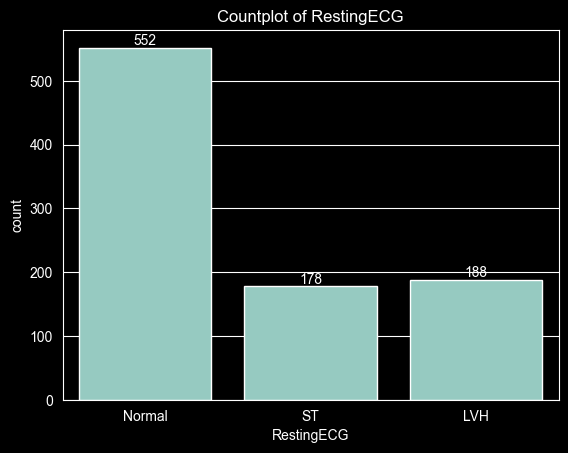

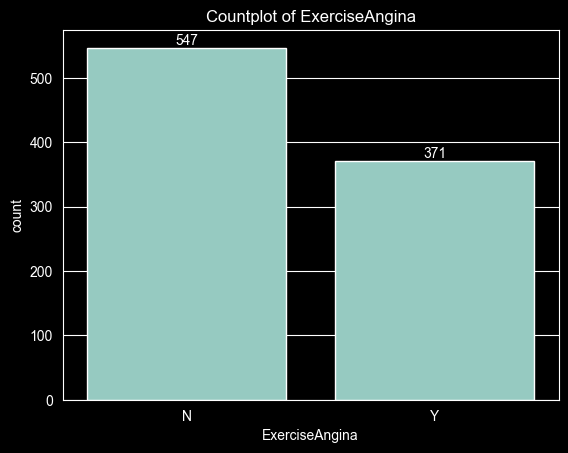

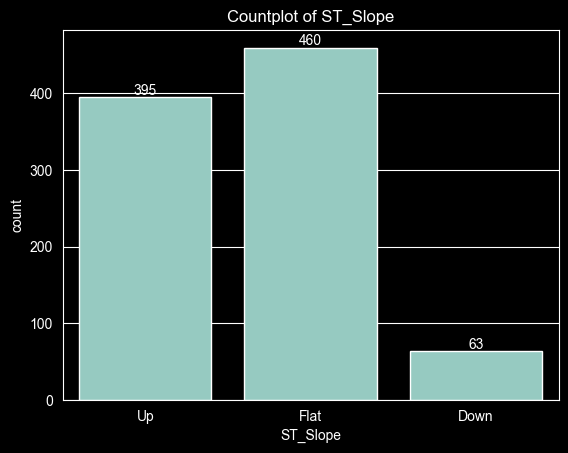

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

# Display countplot visualization for categorical columns
for col in cat_cols:
    ax = sns.countplot(x=col, data=df)
    ax.bar_label(ax.containers[0])
    plt.title(f'Countplot of {col}')
    plt.show()

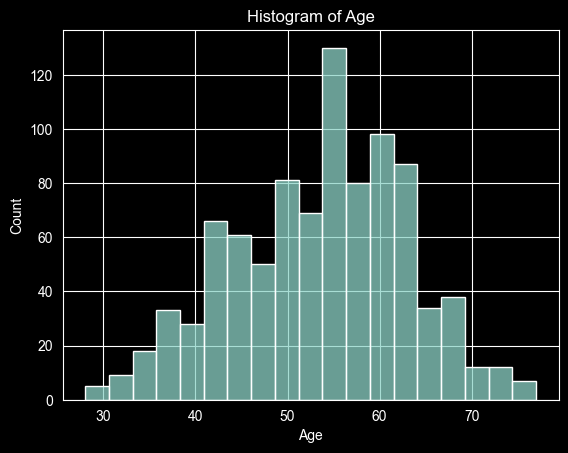

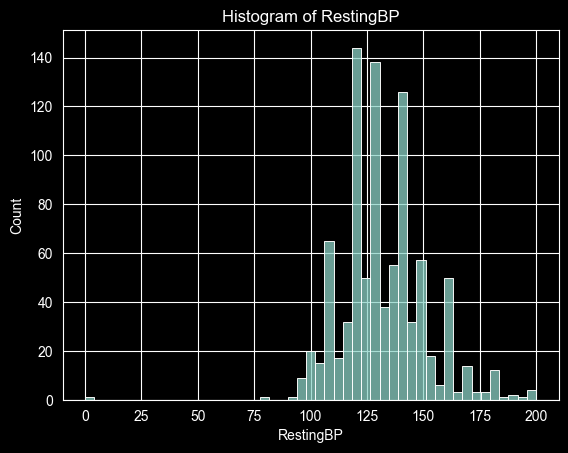

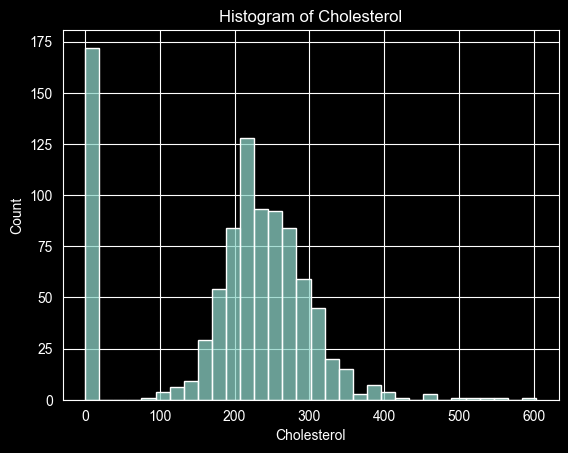

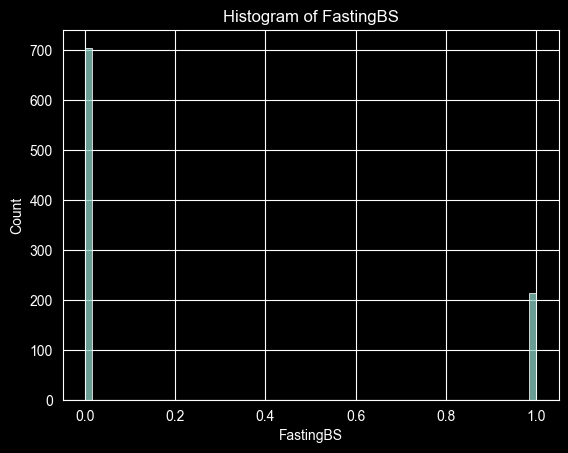

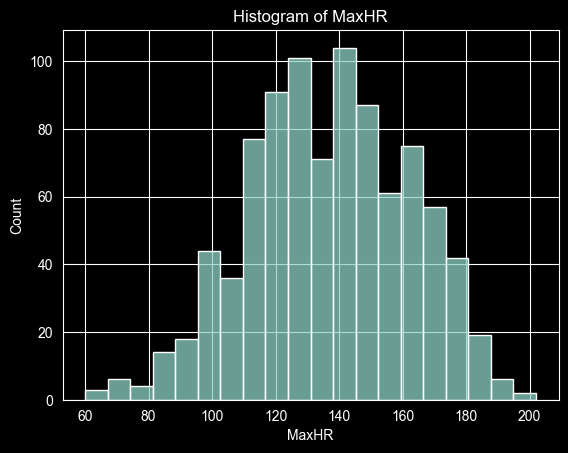

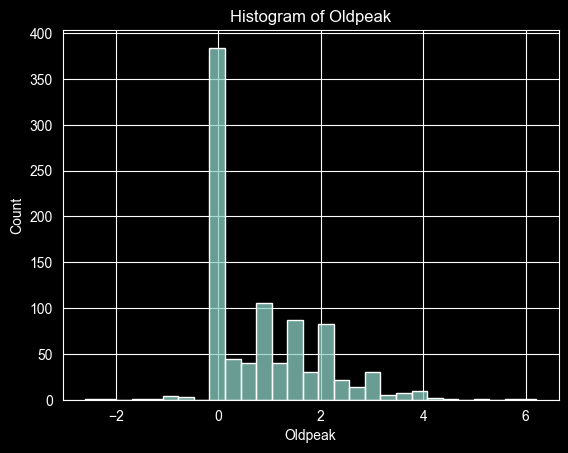

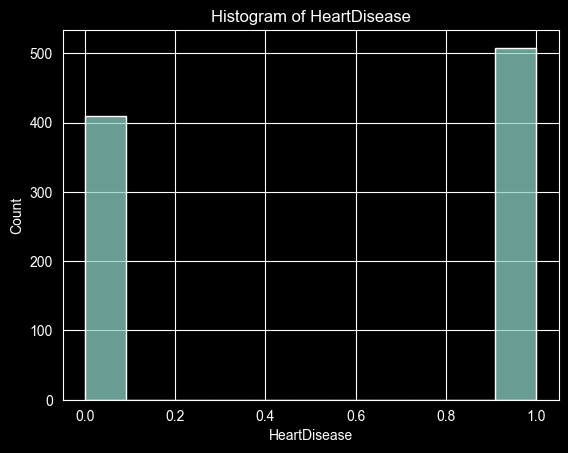

In [7]:
# Display histogram plot for numerical features
for col in num_cols:
    sns.histplot(data=df, x=col)
    plt.title(f'Histogram of {col}')
    plt.show()

# 3. Data Preprocessing

In [8]:
# Check for null values
df.isnull().sum()

Age               0
Sex               0
ChestPainType     0
RestingBP         0
Cholesterol       0
FastingBS         0
RestingECG        0
MaxHR             0
ExerciseAngina    0
Oldpeak           0
ST_Slope          0
HeartDisease      0
dtype: int64

In [9]:
# Check for duplicated values
df.duplicated().sum()

np.int64(0)

<Axes: >

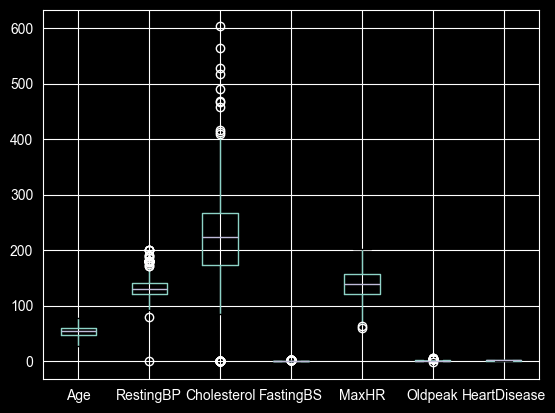

In [10]:
# Check for outliers using boxplot visualization
df.boxplot()

In [11]:
# Check for outliers using IQR methods
for col in num_cols:
    Q1 = df[col].quantile(.25)
    Q3 = df[col].quantile(.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]

    print(outliers[[col]])

Empty DataFrame
Columns: [Age]
Index: []
     RestingBP
109        190
123        180
189        180
190        180
241        200
274        180
275        180
278        180
314         80
365        200
372        185
399        200
411        180
423        180
449          0
475        178
550        172
585        180
592        190
673        174
702        178
725        180
732        200
759        192
774        178
780        180
855        180
880        172
     Cholesterol
28           468
30           518
69           412
76           529
103          466
..           ...
535            0
536            0
616          564
667          417
796          409

[183 rows x 1 columns]
     FastingBS
36           1
38           1
52           1
84           1
86           1
..         ...
887          1
888          1
901          1
911          1
914          1

[214 rows x 1 columns]
     MaxHR
370     63
390     60
     Oldpeak
68       4.0
166      5.0
324     -2.6
500    

In [12]:
# Handling outliers using imputation techniques
for col in num_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Median kolom
    median_value = df[col].median()

    # Imputasi: ganti nilai outlier dengan median
    df.loc[(df[col] < lower_bound) | (df[col] > upper_bound), col] = median_value

In [13]:
from sklearn.preprocessing import LabelEncoder, OneHotEncoder

# le_encoder = LabelEncoder()
ohe_encoder = OneHotEncoder(sparse_output=False)

df_cat_encoded = pd.DataFrame(ohe_encoder.fit_transform(df[cat_cols]), columns=ohe_encoder.get_feature_names_out())

In [14]:
df_cat_encoded.head()

,Sex_F,Sex_M,ChestPainType_ASY,ChestPainType_ATA,ChestPainType_NAP,ChestPainType_TA,RestingECG_LVH,RestingECG_Normal,RestingECG_ST,ExerciseAngina_N,ExerciseAngina_Y,ST_Slope_Down,ST_Slope_Flat,ST_Slope_Up
0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0
1,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0
2,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0
3,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0
4,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0


In [15]:
# Combine the preprocessed features into single dataframe
df_cleaned = pd.concat([df[num_cols], df_cat_encoded], axis=1)

In [16]:
# Manual label encoding for 'HeartDisease'
df_cleaned['HeartDisease'] = df_cleaned['HeartDisease'].map({
    0: 'Not Heart Disease',
    1: 'Heart Disease'
})

# 4. Model Selection

In [17]:
from sklearn.model_selection import train_test_split

# Data splitting
X = df_cleaned.drop('HeartDisease', axis=1)
y = df_cleaned['HeartDisease']

# Split dataset into training set and testing set
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [18]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report

models = [
    LogisticRegression(),
    SVC(),
    DecisionTreeClassifier(),
]

for model in models:
    model.fit(X_train, y_train)

    y_pred_train = model.predict(X_train)
    y_pred_test = model.predict(X_test)

    train_cr = classification_report(y_train, y_pred_train)
    test_cr = classification_report(y_test, y_pred_test)

    print(f'Training Set Classification Report of {model}:')
    print(train_cr)
    print(f'Testing Set Classification Report of {model}:')
    print(test_cr)

C:\Users\ThinkPad\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\linear_model\_logistic.py:406: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Training Set Classification Report of LogisticRegression():
                   precision    recall  f1-score   support

    Heart Disease       0.86      0.88      0.87       401
Not Heart Disease       0.85      0.83      0.84       333

         accuracy                           0.86       734
        macro avg       0.86      0.85      0.86       734
     weighted avg       0.86      0.86      0.86       734

Testing Set Classification Report of LogisticRegression():
                   precision    recall  f1-score   support

    Heart Disease       0.91      0.82      0.86       107
Not Heart Disease       0.78      0.88      0.83        77

         accuracy                           0.85       184
        macro avg       0.84      0.85      0.85       184
     weighted avg       0.85      0.85      0.85       184

Training Set Classification Report of SVC():
                   precision    recall  f1-score   support

    Heart Disease       0.70      0.77      0.73       401
Not

# 5. Saving the Model

In [20]:
import pickle
import joblib

# Menginisiasi ulang model regresi logistik
model = LogisticRegression()

# Melatih ulang model regresi logistik
model.fit(X_train, y_train)

with open('Logistic_Regression_Model_Pickle.pkl', 'wb') as file:
    pickle.dump(model, file)
joblib.dump(model, 'Logistic_Regression_Model_Joblib.joblib')

C:\Users\ThinkPad\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\linear_model\_logistic.py:406: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


['Logistic_Regression_Model_Joblib.joblib']